# RMS cliff sweep: local analysis

After downloading new results with `rsync`, choose the run below and **Run All**. You can also rerun the **Refresh and plot** cell by itself after setup: it always reloads the raw case checkpoints.

The plot shows the mean applied residual across available aberration cases, with **±1 sample standard deviation** error bars (`ddof=1`). Each AO loop has its own panel with shared linear axis scaling and a dashed **y=x** reference. Partial runs are supported; missing cases are excluded, and single-case groups have no estimated standard deviation. No optimization is run.

Use the `phase_diversity_env` Python kernel. See [README.md](README.md) for the download command.


In [15]:
from pathlib import Path
import importlib
import sys

ROOT = Path.cwd().resolve()
while not ((ROOT / "utils").is_dir() and (ROOT / "optimization").is_dir()):
    if ROOT == ROOT.parent:
        raise RuntimeError("Open this notebook inside the fall_2026_lab repository.")
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display

# Show the figures inline when running in Jupyter.
shell = get_ipython()
if shell is not None:
    shell.run_line_magic("matplotlib", "inline")

from systematic_testing.rms_cliff_sweep import analyze as sweep_helpers
from systematic_testing.correction_examples import plot_pd_iteration_rms as rms_plots
importlib.reload(sweep_helpers)
importlib.reload(rms_plots)
print("Repository:", ROOT)


Repository: /Users/maxwatzky/Documents/GitHub/fall_2026_lab


## Choose the downloaded run

Keep `RUN_DIR` pointed at the same run while downloading more cases. Set a different job ID here when analyzing another sweep. `None` axis limits let the shared helper choose them from the available data; explicit limits still apply equally to all three panels.


In [16]:
RUN_DIR = ROOT / "results/bouchet/rms_cliff_sweep/29590918"
OUTPUT_DIR = RUN_DIR / "analysis"

METRIC = "residual_rms"  # Or "estimation_rms" for estimation error before clipping.
USE_TEX = True
X_LIMITS = None  # Example: (0.0, 0.5)
Y_LIMITS = None  # Example: (0.0, 0.5)

print("Reading:", RUN_DIR)
print("Exports:", OUTPUT_DIR)


Reading: /Users/maxwatzky/Documents/GitHub/fall_2026_lab/results/bouchet/rms_cliff_sweep/29590918
Exports: /Users/maxwatzky/Documents/GitHub/fall_2026_lab/results/bouchet/rms_cliff_sweep/29590918/analysis


## Refresh and plot

Rerun this cell after each download. It reads `case_*/run.json` and `results.npz` directly, averages the currently available cases at each initial RMS, displays the plot, and updates the PNG/PDF exports plus the numerical summary tables.

The shared plotting helper preserves the established colors, `bmh` style, LaTeX text, and 300 DPI exports. Error bars extending below zero are outside the displayed nonnegative RMS axis.


Three-loop cases: 128/400; completed AO fits: 395/1200
Saved: /Users/maxwatzky/Documents/GitHub/fall_2026_lab/results/bouchet/rms_cliff_sweep/29590918/analysis/residual_vs_initial_rms_panels.pdf


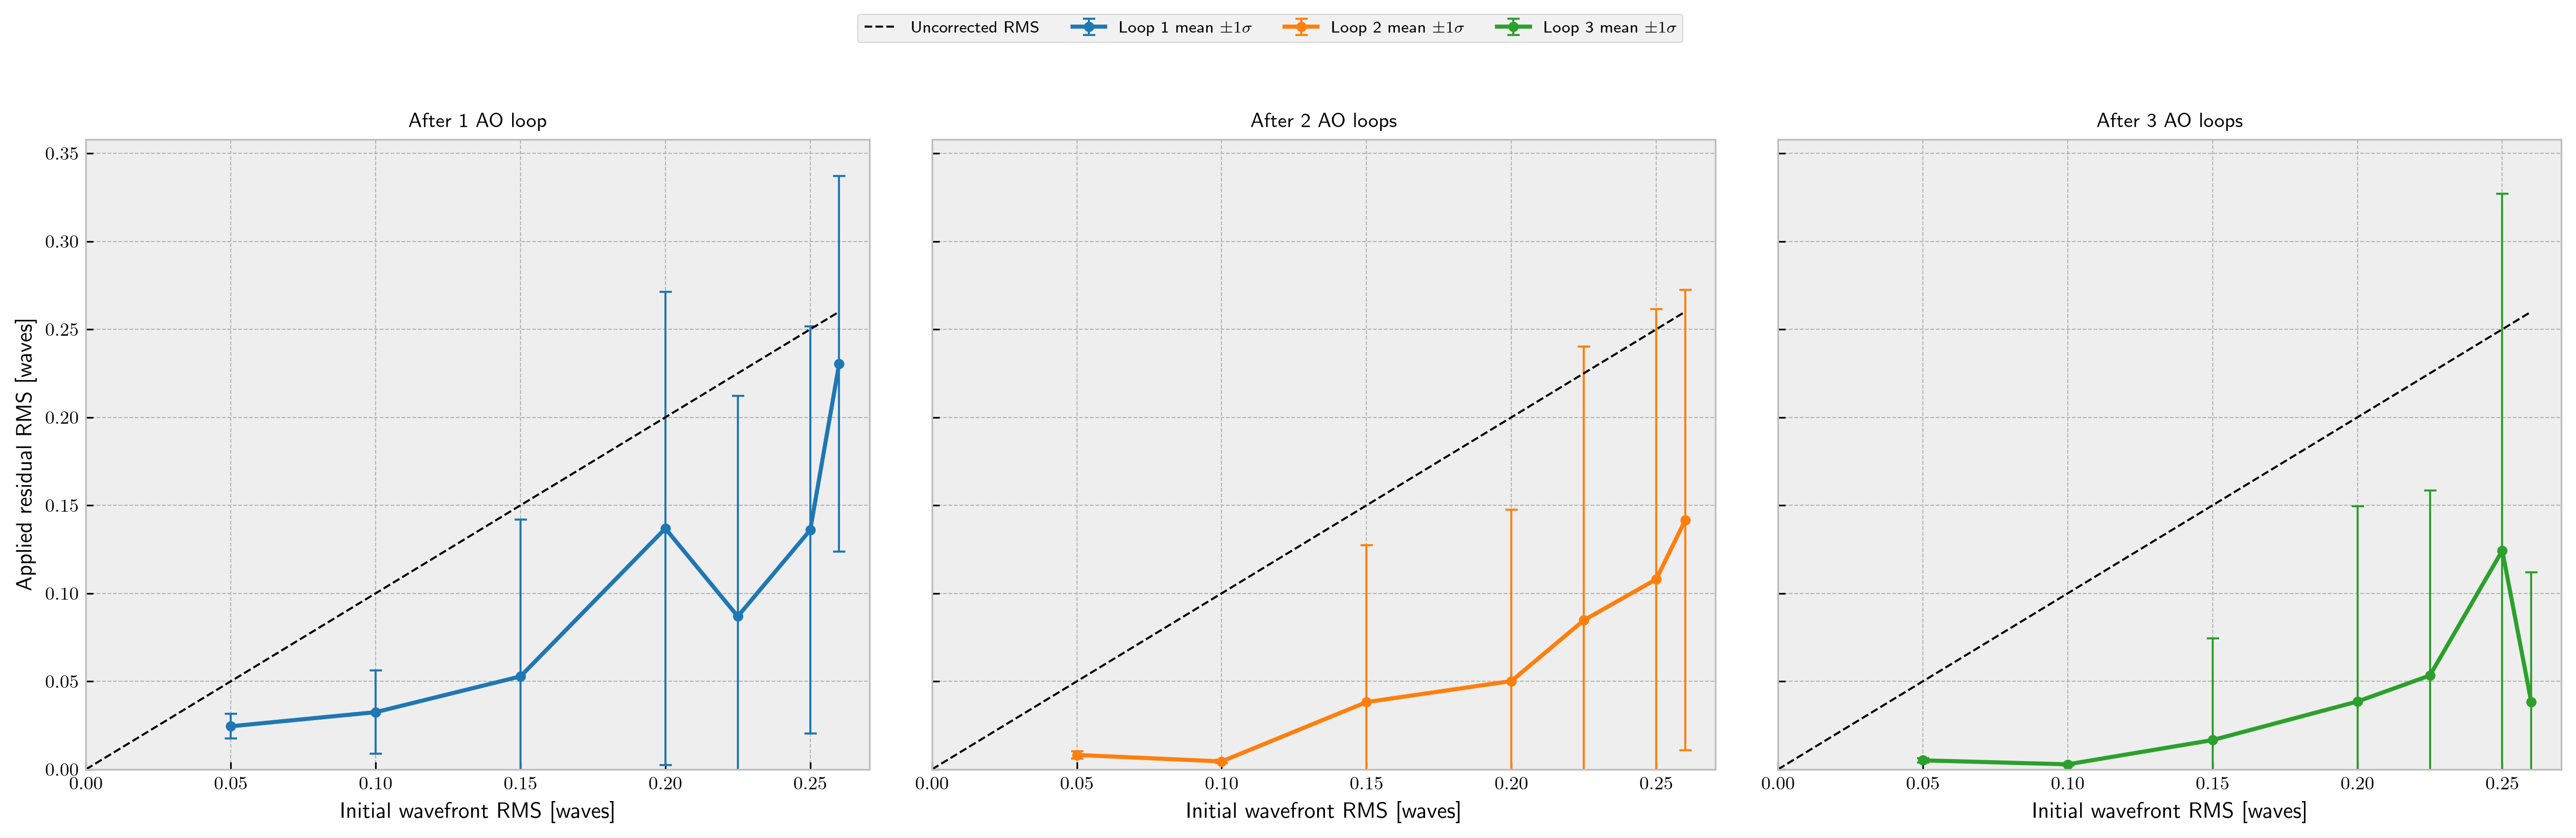

In [17]:
# Reload both code and data so rerunning this cell uses the latest local files.
importlib.reload(sweep_helpers)
importlib.reload(rms_plots)
sweep = sweep_helpers.load_sweep(RUN_DIR)

labels = {
    "residual_rms": ("Applied residual RMS [waves]", "residual_vs_initial_rms_panels"),
    "estimation_rms": ("Estimation RMS error before clipping [waves]", "estimation_vs_initial_rms_panels"),
}
if METRIC not in labels:
    raise ValueError("Choose residual_rms or estimation_rms.")
ylabel, stem = labels[METRIC]

# The shared helper computes one mean and one sample SD across trials per RMS/loop.
# Display only RMS groups with at least one saved result in the selected metric.
values = sweep[METRIC]
populated = np.any(np.isfinite(values), axis=(1, 2))
if not populated.any():
    raise ValueError("No completed AO fits are available yet. Download their checkpoints first.")

finished_cases = int(np.all(sweep["completed"], axis=-1).sum())
print(f"Three-loop cases: {finished_cases}/{sweep['status'].size}; "
      f"completed AO fits: {sweep['completed'].sum()}/{sweep['completed'].size}")

fig, axes = rms_plots.plot_residual_vs_initial_rms(
    sweep["initial_rms"][populated],
    values[populated],
    loop_indices=[0, 1, 2],
    ylabel=ylabel,
    plot_kind="mean",
    separate_loops=True,
    log_rms=False,
    reference_rms=None,
    show_uncorrected=True,
    use_tex=USE_TEX,
)

# These axes are shared: changing the first changes all three.
if X_LIMITS is not None:
    axes[0].set_xlim(*X_LIMITS)
if Y_LIMITS is not None:
    axes[0].set_ylim(*Y_LIMITS)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
sweep_helpers.write_tables(sweep, OUTPUT_DIR)
for extension in ("png", "pdf"):
    fig.savefig(OUTPUT_DIR / f"{stem}.{extension}", dpi=300)

print("Saved:", OUTPUT_DIR / f"{stem}.pdf")
display(fig)
plt.close(fig)


## Coverage and statistics

Counts are separate for each AO loop because a running case may have saved only its first or second fit. Rows with no acquired results are omitted here. Statistics include every saved finite result, including nonconverged and inaccurate fits.


In [8]:
counts = sweep["completed"].sum(axis=1)
coverage = pd.DataFrame({
    "Initial RMS [waves]": sweep["initial_rms"],
    "After loop 1": counts[:, 0],
    "After loop 2": counts[:, 1],
    "After loop 3": counts[:, 2],
    "Expected trials": sweep["config"]["trials"],
})
display(coverage.loc[counts.sum(axis=1) > 0].reset_index(drop=True))

summary = pd.read_csv(OUTPUT_DIR / "summary.csv")
summary = summary.loc[(summary["metric"] == METRIC) & (summary["completed_trials"] > 0)]
display(summary[[
    "initial_rms_waves", "ao_loop", "completed_trials", "mean_rms_waves",
    "std_rms_waves", "median_rms_waves", "fraction_at_least_initial",
    "converged_trials",
]].reset_index(drop=True))


,Initial RMS [waves],After loop 1,After loop 2,After loop 3,Expected trials
0,0.050,20,20,20,20
1,0.100,20,20,20,20
2,0.150,20,20,20,20
3,0.200,20,20,20,20
4,0.225,20,20,20,20
5,0.250,20,20,20,20
6,0.260,7,5,4,20


,initial_rms_waves,ao_loop,completed_trials,mean_rms_waves,std_rms_waves,median_rms_waves,fraction_at_least_initial,converged_trials
0,0.050,1,20,0.024465,0.006993,0.024197,0.000000,20
1,0.050,2,20,0.008175,0.001995,0.008915,0.000000,20
2,0.050,3,20,0.005108,0.001223,0.004782,0.000000,20
3,0.100,1,20,0.032484,0.023697,0.024570,0.050000,20
4,0.100,2,20,0.004499,0.000975,0.004376,0.000000,20
5,0.100,3,20,0.002856,0.000723,0.002727,0.000000,20
6,0.150,1,20,0.052802,0.089134,0.010203,0.200000,20
7,0.150,2,20,0.038217,0.089082,0.002335,0.150000,17
8,0.150,3,20,0.016635,0.057831,0.001659,0.050000,19
9,0.200,1,20,0.136849,0.134341,0.103257,0.450000,19
